### TEL354 - Minería de datos
# Clase 6: Clustering
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase6 import *

# ¿Qué es clustering?

Formar grupos de datos que son "similares".

<div align="center">
    <img src="img/clustering.png" alt="" width="50%" align="center" />
</div>    

In [2]:
data = {'Name': ['Andrew', 'Bernhard', 'Carolina', 'Dennis', 'Eve', 
                 'Fred', 'Gwyneth', 'Hayden', 'Irene', 'James'],
        'Letter': ['A','B','C','D','E','F','G','H','I','J'],
        'Age': [55, 43, 37, 82, 23, 46, 38, 50, 29, 42],
        'Salary': [10, 20, 50, 30, 32, 50, 42, 40, 45, 41]}

df = pd.DataFrame(data)

# ¿Cómo formar los grupos?

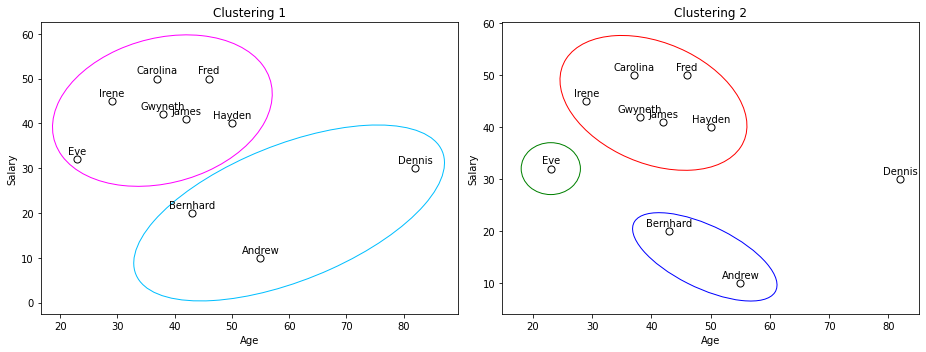

In [3]:
clustering_data(df)

In [4]:
# Select the columns for clustering
data_for_clustering = df[['Age', 'Salary']]

# Convert the selected columns to a NumPy array
X = np.array(data_for_clustering)

# 1. Clustering basado en prototipos

Agrupa los datos alrededor de un **representante central** (prototipo).

### Idea clave:

Cada cluster tiene un punto que lo representa: el **centroide**.

### ¿Cómo funciona?

- asigna puntos al centro más cercano
- ajusta los centros iterativamente

**Intuición:** Clusters = “grupos alrededor de un centro”

# K-Means

1. Seleccionar $K$ puntos como centroides iniciales.
2. Asignar cada dato al centroide más cercano.
3. Recalcular la posición del centroide para cada cluster.
4. Terminar si se cumple criterio de convergencia (centroides no cambian o número de iteraciones). Caso contrario, volver al paso 2.

## Inercia

La inercia o "Sum of Squared Errors" (SSE) representa la suma de las distancias al cuadrado entre cada punto y el centroide al que está asignado. En K-Means, se utiliza para evaluar la calidad del clustering y por ende, se intenta minimizar:
    
$$\mathbf{SSE} = \sum\limits_{i=1}^K \sum\limits_{\mathbf{x} \in C_i} dist(\mathbf{x},c_i)^2$$

donde $dist$ es la distancia Euclidiana y $c_i$ es el centroide del cluster $C_i$ ($i$-ésimo cluster).

## ¿Qué optimiza K-Means?

K-Means busca minimizar: la distancia entre los puntos y su centroide.

### Función objetivo:

Minimizar la **Suma de Errores Cuadráticos (SSE)**.

- clusters compactos
- puntos cerca del centro

**Importante:** K-Means NO garantiza el óptimo global (depende de la inicialización).

# Ejemplo K-Means

In [5]:
kmeans_visualization(data=X, centroids=[(20,20),(50,80)], annotations=df['Name'], font_size=8, x_label='Age', y_label='Salary')

interactive(children=(IntSlider(value=0, description='Iteración', max=5), Output()), _dom_classes=('widget-int…

## Problema de inicialización

El resultado de K-Means depende de: los centroides iniciales.

### Puede pasar:

- diferentes ejecuciones → diferentes clusters
- soluciones subóptimas

**Solución:**

- usar múltiples inicializaciones
- K-Means++

# Criterio para elegir el número de clusters

El método del codo busca determinar visualmente el número óptimo de clusters evaluando la inercia de la agrupación para un rango de valores. Se elige el punto de inflexión en la curva, formando un "codo" en el gráfico, como el número óptimo de clusters.

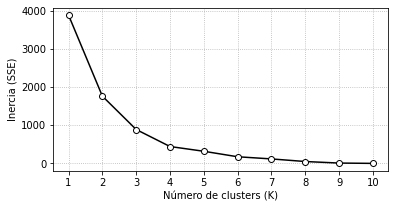

In [6]:
elbow(X,10)

# Limitaciones de K-Means

- Forma grupos convexos.
- Sufre en altas dimensiones.
- No detecta ruido o valores atípicos (outliers).

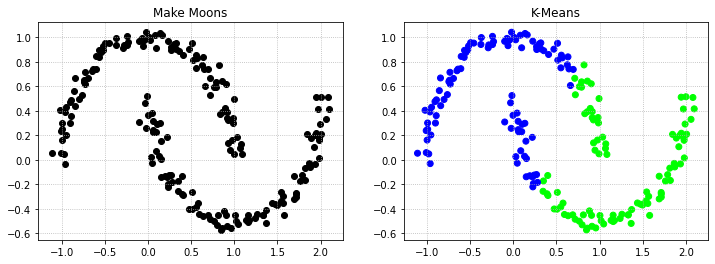

In [7]:
X_moons, _ = make_moons(200, noise=0.05)
plot_kmeans_moons(X_moons, k=2)

# 2. Clustering basado en densidad

Identifica clusters como regiones donde hay **alta concentración de puntos**.

### Idea clave:

- muchos puntos juntos → cluster
- pocos puntos → ruido

### No necesita:

❌ número de clusters ($k$)

**Intuición:** Clusters = “zonas densas separadas por regiones vacías”.

## DBSCAN

DBSCAN busca: regiones densas de puntos.

### Idea clave:

- si hay muchos puntos juntos → cluster
- si no → ruido

A diferencia de K-Means:

- NO asume forma esférica
- detecta formas arbitrarias

## Definiciones

- **Core:** si tiene al menos <tt>MinPts</tt> dentro de un radio <tt>Eps</tt>.
- **Border:** tiene menos de <tt>MinPts</tt> dentro de un radio <tt>Eps</tt>, pero está en el vecindario de un core.
- **Noise:** no es core ni border.

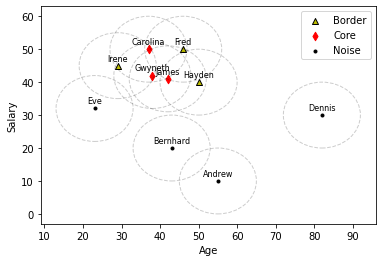

In [8]:
density_based_points(X, Eps=10, MinPts=4, annotations=df['Name'], font_size=8, x_label='Age', y_label='Salary')

# Algoritmo DBSCAN

1. Clasificar los datos como Core, Border o Noise de acuerdo a <tt>Eps</tt> y <tt>MinPts</tt>.
2. Generar un cluster para cada Core.
3. Conectar en un mismo cluster los Core que están a distancia menor que <tt>Eps<tt>.
4. Asignar los Border al cluster de su Core.

# Ejemplo DBSCAN

In [9]:
dbscan_visualization(data=X, Eps=(1,25,1,1), annotations=df['Name'], font_size=8, x_label='Age', y_label='Salary')

interactive(children=(FloatSlider(value=1.0, description='Eps', max=25.0, min=1.0, step=1.0), IntSlider(value=…

In [10]:
dbscan_visualization(data=X_moons, Eps=(0.1,1,0.1,0.3), MinPts=(2,10,1,6), scale=0.4)

interactive(children=(FloatSlider(value=0.3, description='Eps', max=1.0, min=0.1), IntSlider(value=6, descript…

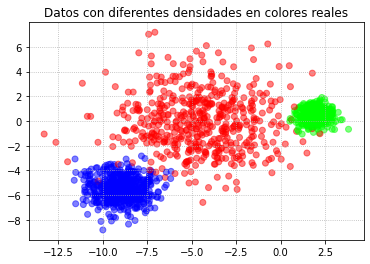

In [11]:
X_blobs, y_blobs = make_blobs(n_samples=1500, cluster_std=[1.0, 2.5, 0.5], random_state=170)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, alpha=0.5, cmap=plt.cm.brg)
plt.title("Datos con diferentes densidades en colores reales")
plt.grid(linestyle="dotted")
plt.show()

In [12]:
dbscan_visualization(data=X_blobs, Eps=(0.1,1,0.1,0.7), MinPts=(1,15,1,9), scale=0.4)

interactive(children=(FloatSlider(value=0.7, description='Eps', max=1.0, min=0.1), IntSlider(value=9, descript…

## Limitaciones de DBSCAN

- Sensible a Eps y MinPts
- Difícil con densidades variables
- No escala tan bien en alta dimensión

**Problema clave:** No todos los clusters tienen la misma densidad.

# 3. Clustering jerárquico

Construye clusters de forma **progresiva y jerárquica**.

### Dos enfoques:

- **Aglomerativo** → une clusters
- **Divisivo** → divide clusters


### Idea clave:

Se construye una estructura tipo árbol: **dendrograma**.

**Intuición:** Clusters dentro de clusters.

## Enfoques

<div align="center">
<img src="img/hierarquical.png" alt="" width="60%" align="center" />
</div>

# Agglomerative Hierarchical Clustering

1. Calcular la matriz de proximidad.
2. REPETIR HASTA que quede un solo cluster:
    1. Combinar los dos clusters más cercanos.
    2. Actualizar la matriz de proximidad entre el nuevo cluster y los anteriores.    

## ¿Cómo medimos distancia entre clusters? (🔗 linkage)

- **Single** → punto más cercano
- **Complete** → punto más lejano
- **Average** → promedio
- **Ward** → minimiza varianza


## Linkage

Los siguientes métodos de vinculación se utilizan para calcular la distancia entre dos clusters.

<div align="center">
<img src="img/linkage.png" alt="" width="100%" align="center" />
</div>


In [13]:
hac_visualization(X, method='ward', labels=list(df['Name']), leaf_rotation=90, leaf_font_size=9)

interactive(children=(IntSlider(value=0, description='Nivel', max=9), Output()), _dom_classes=('widget-interac…

## 🌳 ¿Cómo interpretar el dendrograma?

- eje vertical → distancia entre clusters
- fusiones bajas → clusters similares
- fusiones altas → clusters distintos

### ¿Dónde cortar?

Trazando una línea horizontal (eso define el número de clusters).

# Ejemplos HAC

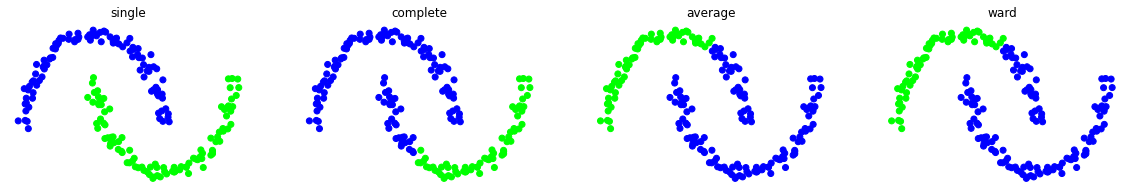

In [14]:
comparing_hac(X_moons, 2)

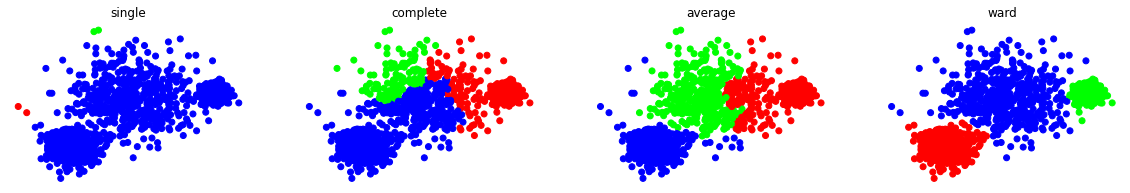

In [15]:
comparing_hac(X_blobs, 3)

## Comparación de algoritmos

| Método | Ventajas | Desventajas |
|--------|--------|------------|
| K-Means | Rápido, simple | Asume clusters esféricos |
| DBSCAN | Detecta ruido, formas complejas | Sensible a parámetros |
| HAC | No necesita $k$ | Costoso computacionalmente |